# Missing Values
## Height, Weight and MUAC
* Mid-Upper Arm Circumference. It is a measurement of the circumference of the upper arm at the midpoint between the shoulder and elbow. This measurement is used as an indicator of nutritional status and to diagnose malnutrition.
** notes: Associated with weight, height and age? use the same philosophy??

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
data = pd.read_csv("../../SyntheticData_Training.csv")
data = data.iloc[:, 1:] # remove id column
target = data.columns[-1] # save target column

In [2]:
# some constants
features = [feature for feature in data.columns.tolist() if not feature.startswith("admitabx")]
numerical_columns = data[features].select_dtypes(include=["int64", "float64"]).columns

In [3]:
data_dictionary = pd.read_csv("../../SyntheticData_DataDictionary_V1.csv")
data_dictionary[['Data Type', 'Variable Source']] = data_dictionary['Variable Type'].str.replace(r'[()]', '', regex=True).str.split('\n', expand=True)
data_dictionary.drop(columns=['Variable Type'], inplace=True)
with pd.option_context('display.max_colwidth', None, 'display.max_rows', None, 'display.max_columns', None):
    # Filter the data_dictionary based on two conditions and display the result
    display(
        data_dictionary[
            (data_dictionary["Collection Type"] == "Admission") & 
            (data_dictionary["Missing Pattern"] != "No missing values")
        ]
    )

,Collection Type,Variable Name,Field Label,Missing Pattern,Details,Data Type,Variable Source
3,Admission,height_cm_adm,Height or length (in cm),14 missing values\n(0.5%),NaN,Continuous,Clinical
4,Admission,weight_kg_adm,Weight (in kg),9 missing values\n(0.3%),NaN,Continuous,Clinical
5,Admission,muac_mm_adm,MUAC (in mm),13 missing values\n(0.5%),NaN,Continuous,Clinical
6,Admission,hr_bpm_adm,Heart rate,1 missing value\n(0.0%),NaN,Continuous,Clinical
7,Admission,rr_brpm_app_adm,Respiratory rate,5 missing values\n(0.2%),NaN,Continuous,Clinical
8,Admission,sysbp_mmhg_adm,Systolic blood pressure,2 missing values\n(0.1%),NaN,Continuous,Clinical
9,Admission,diasbp_mmhg_adm,Diastolic blood pressure,1 missing value\n(0.0%),NaN,Continuous,Clinical
10,Admission,temp_c_adm,Axillary temperature (Celsius),1 missing value\n(0.0%),NaN,Continuous,Clinical
11,Admission,spo2site1_pc_oxi_adm,Oxygen saturation (measure 1),4 missing values\n(0.2%),NaN,Continuous,Clinical
12,Admission,spo2site2_pc_oxi_adm,Oxygen saturation (measure 2),205 missing values\n(7.6%),NaN,Continuous,Clinical


muac_mm_adm


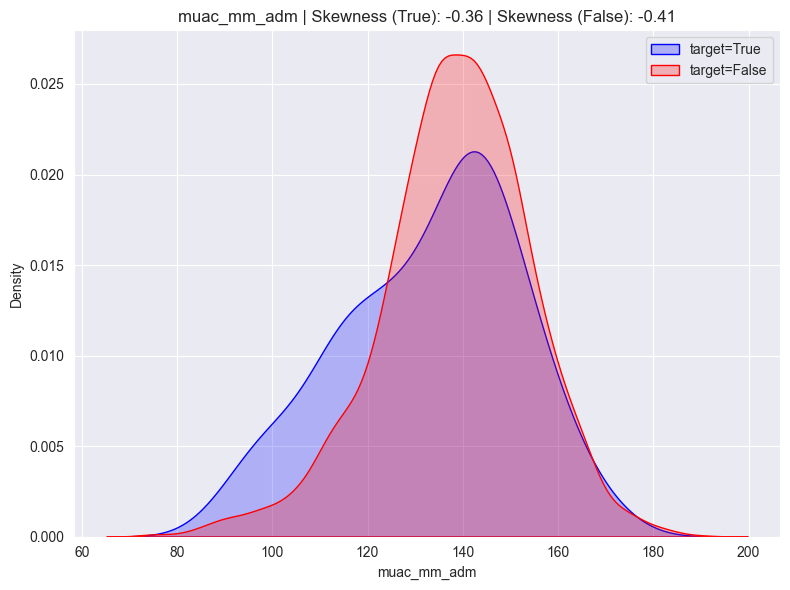

Point-Biserial Correlation: -0.0660269474543354 (p-value: 0.0006359623992254585) - Statistically Significant
T-test Statistic: -2.9387840436001267 (p-value: 0.003938283988197262) - Statistically Significant
Odds Ratio (Logistic Regression): 0.9843228687784816 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.0660269474543354 (p-value: 0.0006359623992254585) - Statistically Significant
weight_kg_adm


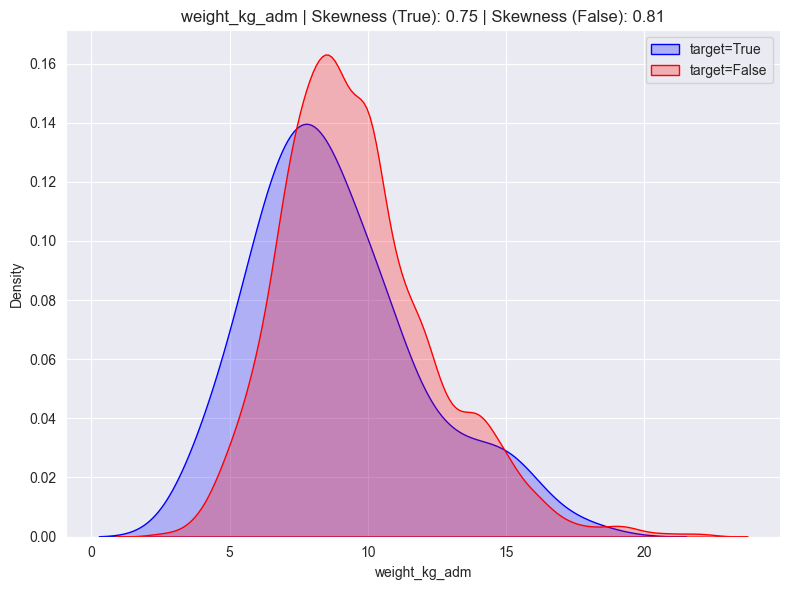

Point-Biserial Correlation: -0.053830153819157234 (p-value: 0.0053383133817236795) - Statistically Significant
T-test Statistic: -2.577737097907716 (p-value: 0.011115415030141943) - Statistically Significant
Odds Ratio (Logistic Regression): 0.9219834777719854 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.053830153819157234 (p-value: 0.0053383133817236795) - Statistically Significant
height_cm_adm


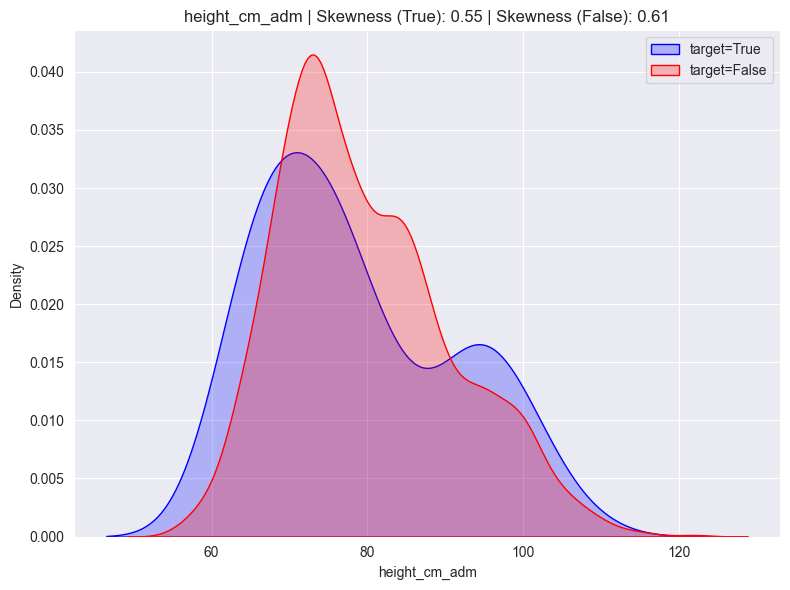

Point-Biserial Correlation: -0.01876909543742694 (p-value: 0.3321301789851805) - Not Statistically Significant
T-test Statistic: -0.8683969295194517 (p-value: 0.3869120172792191) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.9933226172149432 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.01876909543742694 (p-value: 0.3321301789851805) - Not Statistically Significant
agecalc_adm


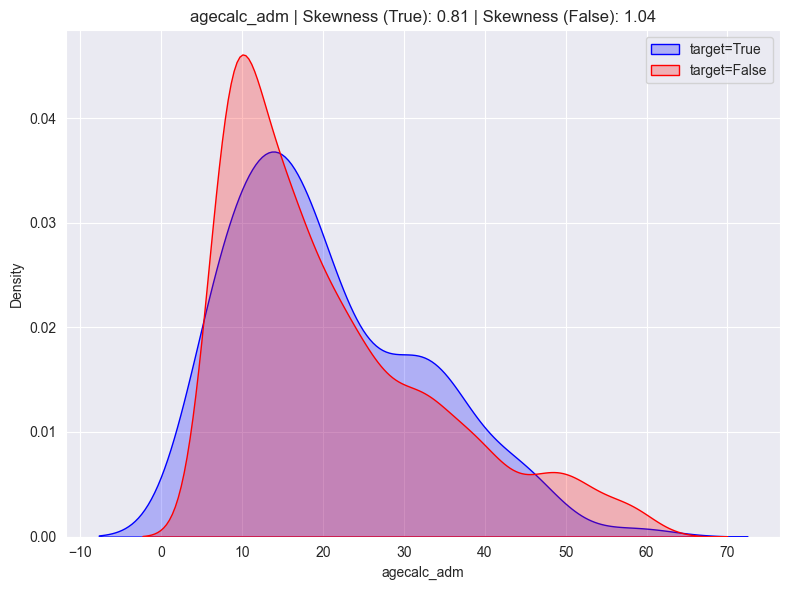

Point-Biserial Correlation: -0.00831315101347127 (p-value: 0.6667232216904414) - Not Statistically Significant
T-test Statistic: -0.47520434421612406 (p-value: 0.6354270194998034) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.9934559952184693 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.00831315101347127 (p-value: 0.6667232216904414) - Not Statistically Significant


In [4]:
# before adding missing values
from helper_function import *
for f in ["muac_mm_adm", "weight_kg_adm", "height_cm_adm", "agecalc_adm"]:
    print(f)
    results = feature_inspection(data, f, target)

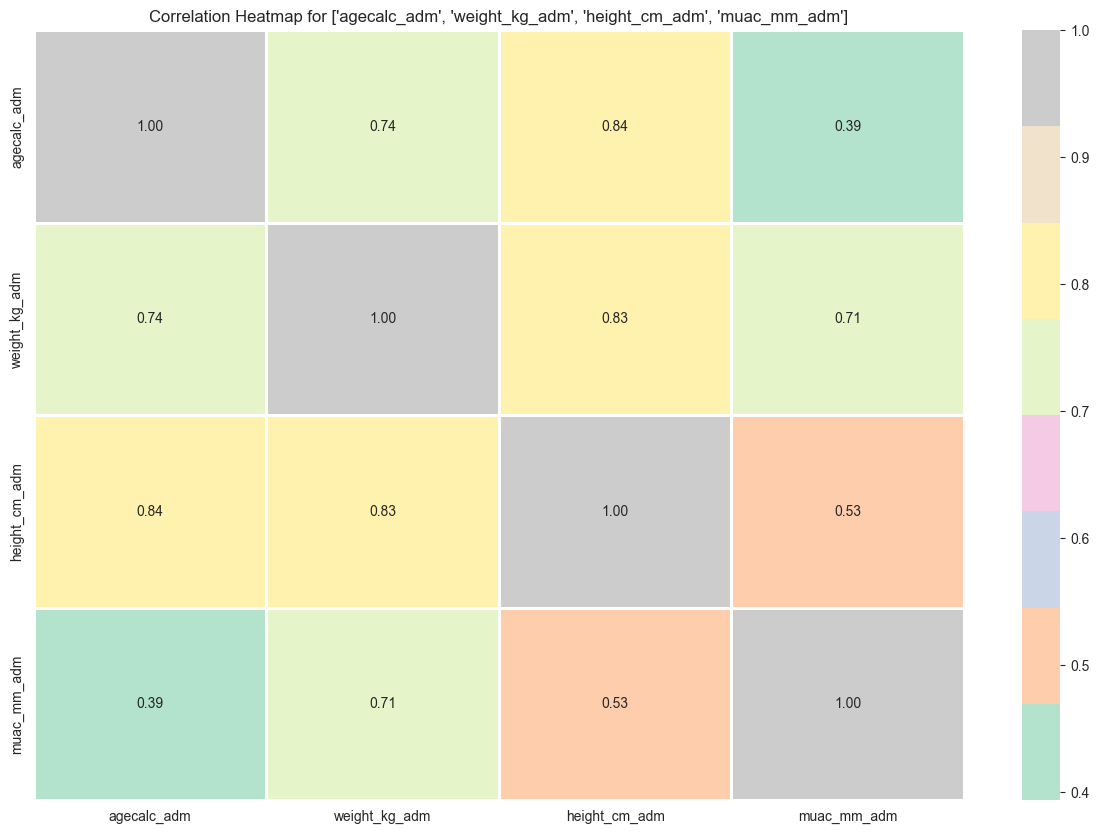

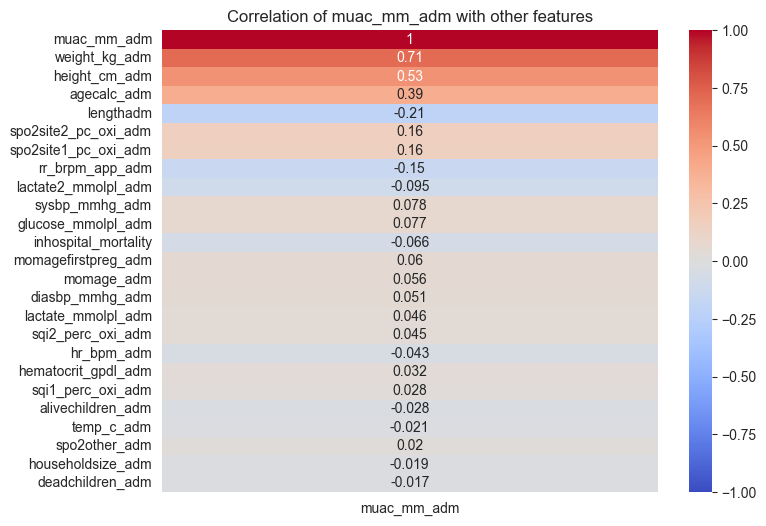

In [5]:
# Assuming 'df' is your DataFrame
plt.figure(figsize=(15, 10))

numerical_features = ["agecalc_adm", "weight_kg_adm", "height_cm_adm", "muac_mm_adm"]

# Using Seaborn to create a heatmap
sns.heatmap(data[numerical_features].corr(), annot=True, fmt='.2f', cmap='Pastel2', linewidths=2)

plt.title(f'Correlation Heatmap for {numerical_features}')
plt.show()



# Select the feature you want to focus on (e.g., 'sepal_length')
target_feature = "muac_mm_adm"

# Calculate the correlation of this feature with others
correlation = data[numerical_columns].corr()[[target_feature]]
correlation = correlation.sort_values(by=target_feature, key=abs, ascending=False)
# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', vmin=-1, vmax=1, cbar=True)

# Customize the plot
plt.title(f'Correlation of {target_feature} with other features')
plt.show()

### Filling missing height and weight

In [6]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler

df = data.copy()
# Step 1: Create a mask for missing values
missing_mask = df[["weight_kg_adm", "height_cm_adm"]].isna()
display(df[["weight_kg_adm", "height_cm_adm"]].info())

# Step 2: Scale the features using MinMaxScaler
scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(df[["agecalc_adm", "weight_kg_adm", "height_cm_adm"]])

# Step 3: Apply KNNImputer
imputer = KNNImputer(n_neighbors=3)
scaled_imputed = imputer.fit_transform(scaled_features)

# Step 4: Inverse scale the imputed data back to the original scale
imputed_features = scaler.inverse_transform(scaled_imputed)

# Step 5: Add the imputed data back into the DataFrame
df[["agecalc_adm", "weight_kg_adm", "height_cm_adm"]] = imputed_features

# Step 6: Add a "filled" column to indicate which values were filled
df["filled"] = 0  
# Update the "filled" column for imputed data
for col in ["weight_kg_adm", "height_cm_adm"]:
    df.loc[missing_mask[col], "filled"] = 1



print("\nImputed DataFrame:")
display(df[["weight_kg_adm", "height_cm_adm"]].info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   weight_kg_adm  2677 non-null   float64
 1   height_cm_adm  2672 non-null   float64
dtypes: float64(2)
memory usage: 42.1 KB


None


Imputed DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   weight_kg_adm  2686 non-null   float64
 1   height_cm_adm  2686 non-null   float64
dtypes: float64(2)
memory usage: 42.1 KB


None

### Filling missing muac

In [7]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler

df = data.copy()
# Step 1: Create a mask for missing values
missing_mask = df[["muac_mm_adm"]].isna()
display(df[["muac_mm_adm"]].info())

# Step 2: Scale the features using MinMaxScaler
scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(df[["muac_mm_adm", "weight_kg_adm", "height_cm_adm"]])

# Step 3: Apply KNNImputer
imputer = KNNImputer(n_neighbors=3)
scaled_imputed = imputer.fit_transform(scaled_features)

# Step 4: Inverse scale the imputed data back to the original scale
imputed_features = scaler.inverse_transform(scaled_imputed)

# Step 5: Add the imputed data back into the DataFrame
df[["muac_mm_adm", "weight_kg_adm", "height_cm_adm"]] = imputed_features

# Step 6: Add a "filled" column to indicate which values were filled
df["filled_muac"] = 0  
# Update the "filled" column for imputed data
for col in ["muac_mm_adm"]:
    df.loc[missing_mask[col], "filled_muac"] = 1



print("\nImputed DataFrame:")
display(df[["muac_mm_adm"]].info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   muac_mm_adm  2673 non-null   float64
dtypes: float64(1)
memory usage: 21.1 KB


None


Imputed DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   muac_mm_adm  2686 non-null   float64
dtypes: float64(1)
memory usage: 21.1 KB


None

muac_mm_adm


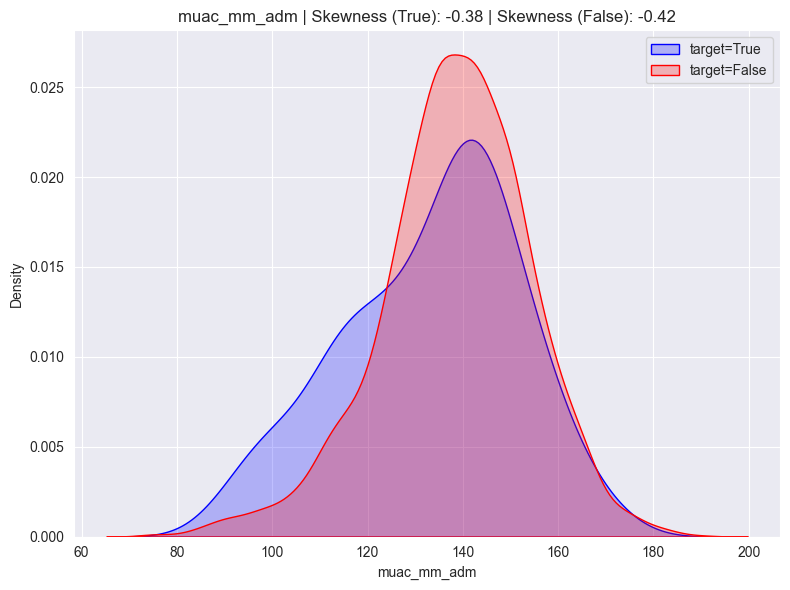

Point-Biserial Correlation: -0.06529864449546688 (p-value: 0.0007085532809784829) - Statistically Significant
T-test Statistic: -2.9417217680001033 (p-value: 0.003884839638655756) - Statistically Significant
Odds Ratio (Logistic Regression): 0.9830599655588965 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.06529864449546688 (p-value: 0.0007085532809784829) - Statistically Significant
weight_kg_adm


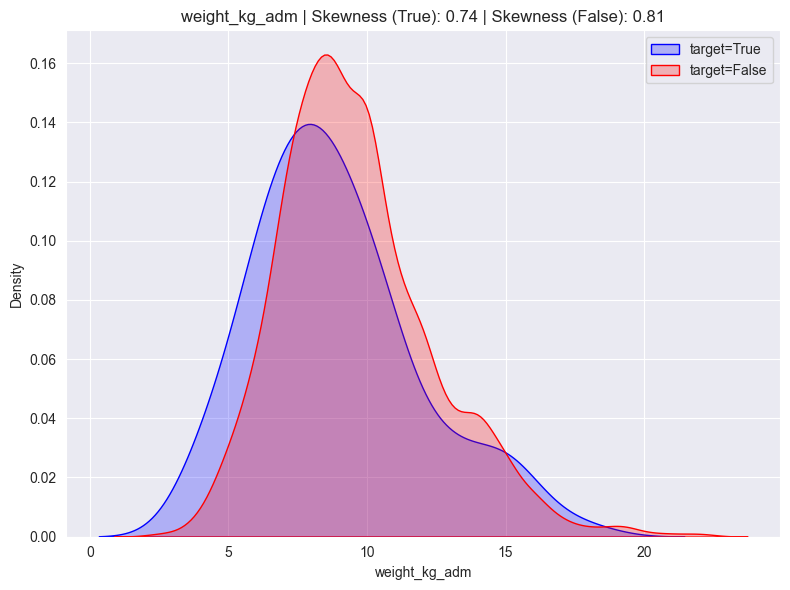

Point-Biserial Correlation: -0.05320321773663975 (p-value: 0.005815377990275654) - Statistically Significant
T-test Statistic: -2.5781352322181155 (p-value: 0.011068951904964009) - Statistically Significant
Odds Ratio (Logistic Regression): 0.9088951736023007 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.05320321773663975 (p-value: 0.005815377990275654) - Statistically Significant
height_cm_adm


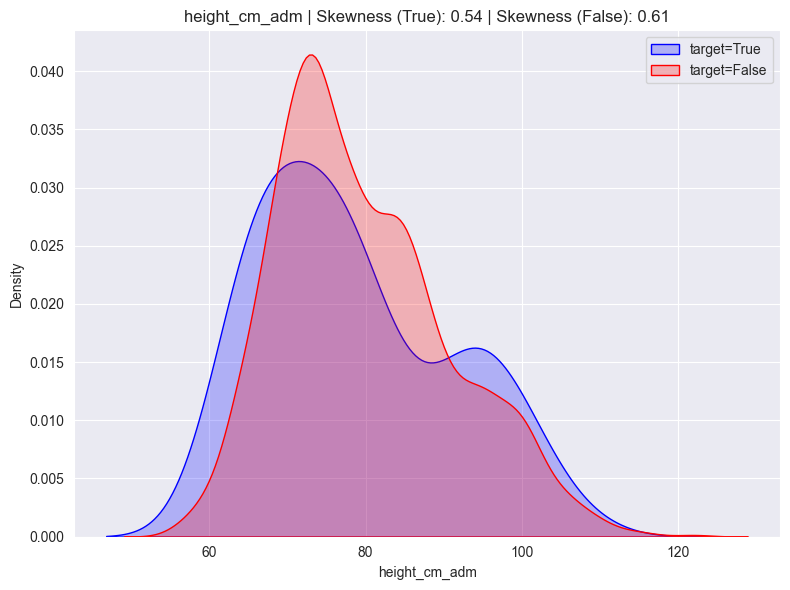

Point-Biserial Correlation: -0.019492924742308543 (p-value: 0.31255356431977066) - Not Statistically Significant
T-test Statistic: -0.9170687245685831 (p-value: 0.36084474584527315) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.9888080373813402 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.019492924742308543 (p-value: 0.31255356431977066) - Not Statistically Significant
agecalc_adm


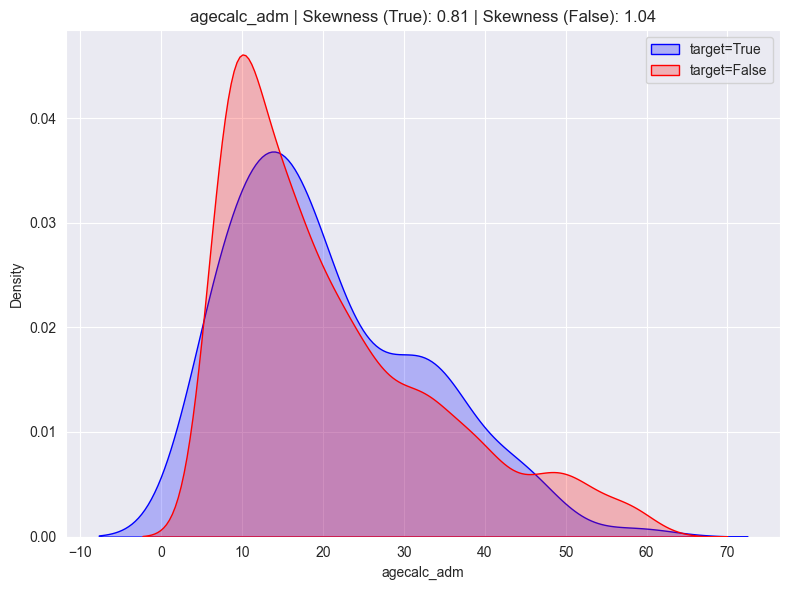

Point-Biserial Correlation: -0.00831315101347127 (p-value: 0.6667232216904414) - Not Statistically Significant
T-test Statistic: -0.47520434421612406 (p-value: 0.6354270194998034) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.9934559952184693 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.00831315101347127 (p-value: 0.6667232216904414) - Not Statistically Significant


In [8]:
from helper_function import *
for f in ["muac_mm_adm", "weight_kg_adm", "height_cm_adm", "agecalc_adm"]:
    print(f)
    results = feature_inspection(df, f, target)